In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.preprocessing import LabelEncoder
import joblib
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r"C:\Users\DeveshNarain\ML project ducat\pred_churned.csv")
df

,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason
0,11098-MAD,Female,30,Yes,Madhya Pradesh,0,31,Deal 1,Yes,No,...,Bank Withdrawal,95.10,6683.40,0.00,0,631.72,7315.12,Stayed,Others,Others
1,11114-PUN,Male,51,No,Punjab,5,9,Deal 5,Yes,No,...,Bank Withdrawal,49.15,169.05,0.00,10,122.37,301.42,Churned,Competitor,Competitor had better devices
2,11167-WES,Female,43,Yes,West Bengal,3,28,Deal 1,Yes,Yes,...,Bank Withdrawal,116.05,8297.50,42.57,110,1872.98,10237.90,Stayed,Others,Others
3,11179-MAH,Male,35,No,Maharashtra,10,12,None,Yes,No,...,Credit Card,84.40,5969.30,0.00,0,219.39,6188.69,Stayed,Others,Others
4,11180-TAM,Male,75,Yes,Tamil Nadu,12,27,Deal 2,Yes,No,...,Credit Card,72.60,4084.35,0.00,140,332.08,4556.43,Stayed,Others,Others
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,25767-TAM,Male,27,Yes,Tamil Nadu,2,19,None,Yes,No,...,Bank Withdrawal,101.90,1667.25,0.00,120,31.80,1819.05,Stayed,Others,Others
996,25784-PUN,Male,40,Yes,Punjab,4,24,Deal 4,Yes,No,...,Credit Card,20.60,330.25,0.00,0,535.04,865.29,Stayed,Others,Others
997,25799-TEL,Female,27,No,Telangana,1,1,Deal 1,Yes,No,...,Credit Card,19.85,1433.80,45.47,0,245.70,1634.03,Stayed,Others,Others
998,25817-UTT,Male,33,No,Uttarakhand,5,30,Deal 2,Yes,Yes,...,Credit Card,80.45,3375.90,0.00,0,727.02,4102.92,Stayed,Others,Others


# Data Preprocessing

In [3]:
# Drop columns that won't be used for prediction
df = df.drop(["Customer_ID","Churn_Category","Churn_Reason"],axis=1)

In [4]:
df.isnull().sum()

Gender                         0
Age                            0
Married                        0
State                          0
Number_of_Referrals            0
Tenure_in_Months               0
Value_Deal                     0
Phone_Service                  0
Multiple_Lines                 0
Internet_Service               0
Internet_Type                  0
Online_Security                0
Online_Backup                  0
Device_Protection_Plan         0
Premium_Support                0
Streaming_TV                   0
Streaming_Movies               0
Streaming_Music                0
Unlimited_Data                 0
Contract                       0
Paperless_Billing              0
Payment_Method                 0
Monthly_Charge                 0
Total_Charges                  0
Total_Refunds                  0
Total_Extra_Data_Charges       0
Total_Long_Distance_Charges    0
Total_Revenue                  0
Customer_Status                0
dtype: int64

In [5]:
df1 = df.copy()

In [6]:
# List of categorical columns to be label encoded
columns_to_encode = [
    'Gender', 'Married', 'State', 'Value_Deal', 'Phone_Service', 'Multiple_Lines',
    'Internet_Service', 'Internet_Type', 'Online_Security', 'Online_Backup',
    'Device_Protection_Plan', 'Premium_Support', 'Streaming_TV', 'Streaming_Movies',
    'Streaming_Music', 'Unlimited_Data', 'Contract', 'Paperless_Billing',
    'Payment_Method'
]

# Encode categorical variables except the target variable
label_encoders = {}
for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    df[column] = label_encoders[column].fit_transform(df[column])

# Manually encode the target variable 'Customer_Status' because using label encoded,
# we would have got '1' for 'stayed' and '0' for 'churned' but we don't want that
df['Customer_Status'] = df['Customer_Status'].map({'Stayed': 0, 'Churned': 1})

In [7]:
df.head()

,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,Internet_Service,...,Contract,Paperless_Billing,Payment_Method,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status
0,0,30,1,11,0,31,0,1,0,1,...,2,0,0,95.10,6683.40,0.00,0,631.72,7315.12,0
1,1,51,0,15,5,9,4,1,0,1,...,0,1,0,49.15,169.05,0.00,10,122.37,301.42,1
2,0,43,1,21,3,28,0,1,1,1,...,2,1,0,116.05,8297.50,42.57,110,1872.98,10237.90,0
3,1,35,0,12,10,12,5,1,0,1,...,2,1,1,84.40,5969.30,0.00,0,219.39,6188.69,0
4,1,75,1,17,12,27,1,1,0,1,...,2,1,1,72.60,4084.35,0.00,140,332.08,4556.43,0


In [8]:
df["Customer_Status"].value_counts()

0    714
1    286
Name: Customer_Status, dtype: int64

In [9]:
# Split data into features and target
X = df.drop('Customer_Status', axis=1)
y = df['Customer_Status']

In [10]:
# !pip install --upgrade scikit-learn imbalanced-learn

In [11]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

# Assuming X and y are your features and labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=42)

# Apply SMOTE to oversample the minority class
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

In [17]:
df["Customer_Status"].value_counts()

0    714
1    286
Name: Customer_Status, dtype: int64

In [23]:
y_train.value_counts()

0    147
1     53
Name: Customer_Status, dtype: int64

In [19]:
y_train_resampled.value_counts()

0    567
1    567
Name: Customer_Status, dtype: int64

In [12]:
# Split data into training and testing sets
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
from xgboost import XGBClassifier

In [14]:
model_params = {
    "XGBoost": {
        "model": XGBClassifier(),
        "params": {
            'n_estimators': [100, 200, 300],
            'max_depth': [3, 5, 7],
            'learning_rate': [0.01, 0.1, 0.2],
        }
    },
    "RandomForest": {
        "model":RandomForestClassifier(),
        "params": {
            'n_estimators': [100, 200, 300],
            'max_depth': [3, 5, 7],
            'min_samples_split': [2, 5, 10]
        }
    }
}

In [24]:
from sklearn.model_selection import GridSearchCV
scores = []
for model,mp in model_params.items():
    clf = GridSearchCV(mp["model"],mp["params"],cv=5,return_train_score=False)
    clf.fit(X_train_resampled,y_train_resampled)
    scores.append({
        "model": model,
        "best_params": clf.best_params_,
        "best_score": clf.best_score_
    })

In [25]:
df_scores = pd.DataFrame(scores)
df_scores

,model,best_params,best_score
0,XGBoost,"{'learning_rate': 0.1, 'max_depth': 7, 'n_esti...",0.868637
1,RandomForest,"{'max_depth': 7, 'min_samples_split': 5, 'n_es...",0.856290


In [26]:
scores

[{'model': 'XGBoost',
  'best_params': {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100},
  'best_score': 0.8686367003235741},
 {'model': 'RandomForest',
  'best_params': {'max_depth': 7, 'min_samples_split': 5, 'n_estimators': 200},
  'best_score': 0.8562902031109898}]

In [27]:
# Initialize the Random Forest Classifier
model = XGBClassifier(learning_rate = 0.1, max_depth = 7, n_estimators = 100)

# Train the model
model.fit(X_train_resampled, y_train_resampled)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [28]:
# Making predictions
y_pred = model.predict(X_test)

In [29]:
# Evaluate the model
print("Confusion Matrix:")
cf = confusion_matrix(y_test, y_pred)
print(cf)

Confusion Matrix:
[[134  13]
 [ 15  38]]


Text(0.5, 23.52222222222222, 'True')

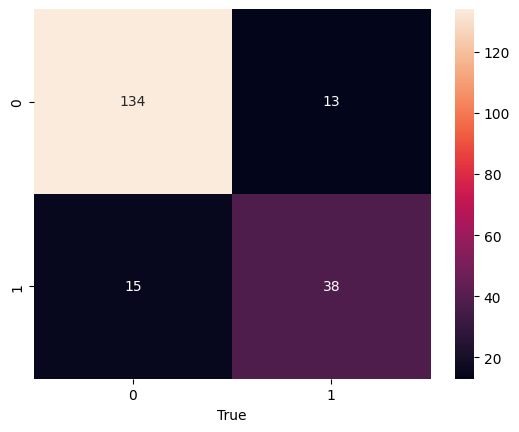

In [30]:
sns.heatmap(cf,annot=True,fmt='d')
plt.xlabel("Predicted")
plt.xlabel("True")

In [31]:
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.91      0.91       147
           1       0.75      0.72      0.73        53

    accuracy                           0.86       200
   macro avg       0.82      0.81      0.82       200
weighted avg       0.86      0.86      0.86       200



In [32]:
# Feature Selection using Feature Importance
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]

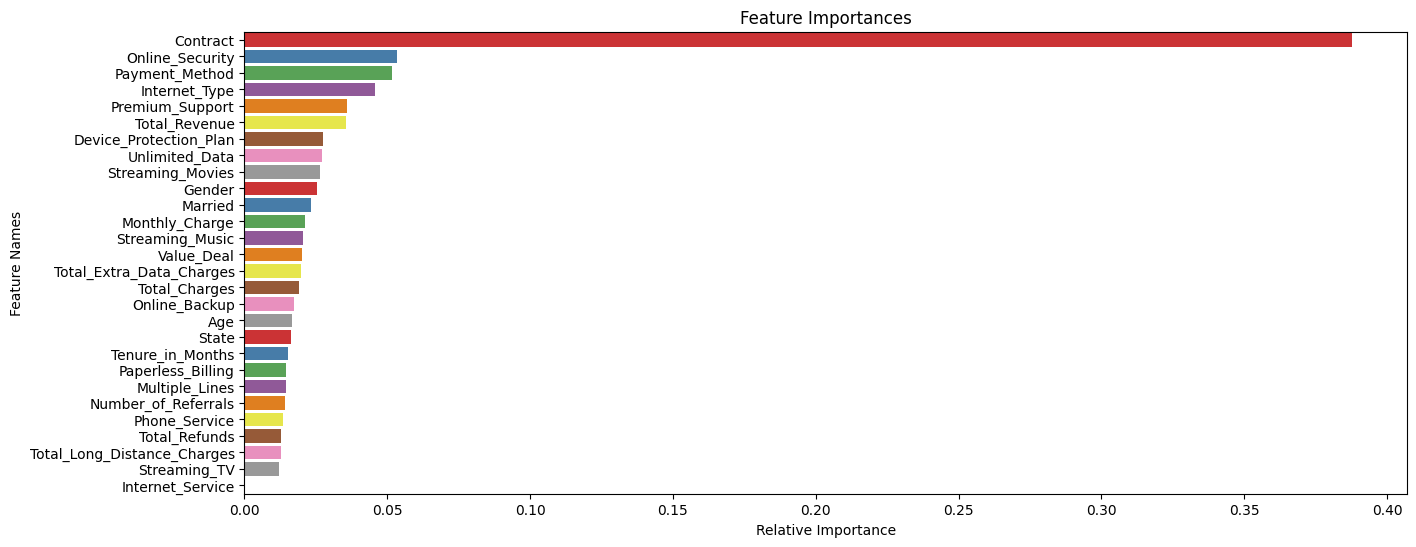

In [33]:
# Plot the feature importances
plt.figure(figsize=(15, 6))
sns.barplot(x=importances[indices], y=X.columns[indices],palette="Set1")
plt.title('Feature Importances')
plt.xlabel('Relative Importance')
plt.ylabel('Feature Names')
plt.show()

# PCA for dimensionality reduction

In [34]:
from sklearn.decomposition import PCA
pca = PCA(n_components=22)

In [35]:
X_pca = pca.fit_transform(X)

In [36]:
X_pca.shape,X.shape

((1000, 22), (1000, 28))

In [37]:
pca.explained_variance_ratio_ # % of important features retained from each column

array([9.56645128e-01, 4.32025418e-02, 6.91490514e-05, 4.36531103e-05,
       2.06650108e-05, 7.94428951e-06, 6.16016581e-06, 2.73281359e-06,
       1.56012131e-06, 1.94073175e-07, 7.09552632e-08, 3.63262829e-08,
       2.27133829e-08, 1.97805116e-08, 1.81802518e-08, 1.67128379e-08,
       1.42991055e-08, 1.33753947e-08, 1.13497690e-08, 1.05244990e-08,
       9.12971449e-09, 8.86038428e-09])

In [38]:
X_train_pca,X_test_pca,y_train_pca,y_test_pca = train_test_split(X_pca,y,
                                                                 test_size=0.2,
                                                                 random_state=42)

# Apply SMOTE to oversample the minority class
smote = SMOTE(random_state=42)
X_train_resampled1, y_train_resampled1 = smote.fit_resample(X_train_pca,
                                                            y_train_pca)

In [39]:
# Initialize the Random Forest Classifier
model = XGBClassifier(learning_rate = 0.1, max_depth = 7, n_estimators = 100)

# Train the model
model.fit(X_train_resampled1, y_train_resampled1)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              gamma=None, grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=7, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=100, n_jobs=None,
              num_parallel_tree=None, random_state=None, ...)

In [40]:
y_train_pred = model.predict(X_train_resampled1)
y_test_pred = model.predict(X_test_pca)

In [41]:
print(classification_report(y_test_pca,y_test_pred))

              precision    recall  f1-score   support

           0       0.89      0.89      0.89       147
           1       0.70      0.70      0.70        53

    accuracy                           0.84       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.84      0.84      0.84       200



In [42]:
# data = pd.read_csv(r"C:\Users\DeveshNarain\ML project ducat\pred_joined.csv")
# data

In [43]:
# data.isnull().sum()

# Exporting results to csv file

In [44]:
# Define the path to the Joiner Data Excel file
file_path = r"C:\Users\DeveshNarain\ML project ducat\pred_joined.csv"

# Read the data from the specified sheet into a pandas DataFrame
new_data = pd.read_csv(file_path)

# Display the first few rows of the fetched data
print(new_data.head())

# Retain the original DataFrame to preserve unencoded columns
original_data = new_data.copy()

# Retain the Customer_ID column
customer_ids = new_data['Customer_ID']

# Drop columns that won't be used for prediction in the encoded DataFrame
new_data = new_data.drop(['Customer_ID', 'Customer_Status', 'Churn_Category', 'Churn_Reason'], axis=1)

# Encode categorical variables using the saved label encoders
for column in new_data.select_dtypes(include=['object']).columns:
    new_data[column] = label_encoders[column].transform(new_data[column])

# applying pca
new_data = pca.fit_transform(new_data)

# Make predictions
new_predictions = model.predict(new_data)

# Add predictions to the original DataFrame
original_data['Customer_Status_Predicted'] = new_predictions

# Filter the DataFrame to include only records predicted as "Churned"
original_data = original_data[original_data['Customer_Status_Predicted'] == 1]

# Save the results
original_data.to_csv(r"C:\Users\DeveshNarain\ML project ducat\Pred.csv", index=False)

  Customer_ID  Gender  Age Married        State  Number_of_Referrals  \
0   11751-TAM  Female   18      No   Tamil Nadu                    5   
1   12056-WES    Male   27      No  West Bengal                    2   
2   12136-RAJ  Female   25     Yes    Rajasthan                    2   
3   12257-ASS  Female   39      No        Assam                    9   
4   12340-DEL  Female   51     Yes        Delhi                    0   

   Tenure_in_Months Value_Deal Phone_Service Multiple_Lines  ...  \
0                 7     Deal 5            No             No  ...   
1                20       None           Yes             No  ...   
2                35       None           Yes             No  ...   
3                 1       None           Yes             No  ...   
4                10       None           Yes             No  ...   

    Payment_Method Monthly_Charge Total_Charges Total_Refunds  \
0     Mailed Check          24.30         38.45           0.0   
1  Bank Withdrawal          

In [45]:
df2 = pd.read_csv(r"C:\Users\DeveshNarain\ML project ducat\Pred.csv")
df2

,Customer_ID,Gender,Age,Married,State,Number_of_Referrals,Tenure_in_Months,Value_Deal,Phone_Service,Multiple_Lines,...,Monthly_Charge,Total_Charges,Total_Refunds,Total_Extra_Data_Charges,Total_Long_Distance_Charges,Total_Revenue,Customer_Status,Churn_Category,Churn_Reason,Customer_Status_Predicted
0,12056-WES,Male,27,No,West Bengal,2,20,None,Yes,No,...,90.40,268.45,0.0,0,94.44,362.89,Joined,Others,Others,1
1,12469-AND,Male,24,Yes,Andhra Pradesh,11,4,None,Yes,No,...,55.30,55.30,0.0,0,36.69,91.99,Joined,Others,Others,1
2,14567-TAM,Male,43,No,Tamil Nadu,1,9,None,Yes,No,...,20.35,20.35,0.0,0,44.09,64.44,Joined,Others,Others,1
3,15591-KAR,Female,26,No,Karnataka,3,31,None,Yes,No,...,20.40,20.40,0.0,0,45.91,66.31,Joined,Others,Others,1
4,15803-UTT,Female,34,No,Uttar Pradesh,6,31,None,Yes,No,...,19.15,19.15,0.0,0,22.37,41.52,Joined,Others,Others,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153,96430-PUN,Male,37,No,Punjab,0,23,None,Yes,No,...,48.75,48.75,0.0,0,26.26,75.01,Joined,Others,Others,1
154,98767-WES,Female,26,No,West Bengal,14,7,None,Yes,No,...,20.05,20.05,0.0,0,11.10,31.15,Joined,Others,Others,1
155,99144-UTT,Female,41,No,Uttar Pradesh,9,20,None,Yes,No,...,19.65,68.35,0.0,0,106.77,175.12,Joined,Others,Others,1
156,99475-KAR,Male,22,Yes,Karnataka,11,11,None,Yes,No,...,51.55,106.20,0.0,0,37.22,143.42,Joined,Others,Others,1


In [46]:
import pandas as pd
d = pd.read_csv(r"C:\Users\DeveshNarain\ML project ducat\Data & Resources\Data\Customer_Data.csv")
d.shape

(6418, 32)